# ClashAdvisor — apresentação da Unidade II

**Daniel Limaverde da Silva**

Este é o notebook que vou usar para explicar meu projeto e mostrar ele funcionando. O ClashAdvisor é um assistente para quem joga *Clash of Clans* e quer consultar sua vila, planejar melhorias e buscar informações.

## 1. Onde está o projeto?

Eu separei o código em arquivos para não misturar as ferramentas, a interface e o funcionamento do agente. Aqui verifico se o notebook está na pasta correta.

In [1]:
import os, sys, socket, subprocess, time, uuid
from pathlib import Path
from urllib.parse import urlparse
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "clashadvisor" / "graph.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "clashadvisor" / "graph.py").exists(), "Abra este notebook na pasta notebooks do projeto."
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Projeto:", ROOT)
print("Ambiente Python:", sys.executable)
for f in ("clashadvisor/graph.py", "clashadvisor/server.py", "clashadvisor/app.py", "scripts/avaliar_agente.py", "skills/analise_perfil/SKILL.md", "skills/planejamento/SKILL.md"):
    print(("OK" if (ROOT/f).exists() else "FALTA"), f)

Projeto: C:\Users\Daniel\Documents\Github\ClashAdvisor
Ambiente Python: c:\Users\Daniel\Documents\Github\ClashAdvisor\.venv\Scripts\python.exe
OK clashadvisor/graph.py
OK clashadvisor/server.py
OK clashadvisor/app.py
OK scripts/avaliar_agente.py
OK skills/analise_perfil/SKILL.md
OK skills/planejamento/SKILL.md


## 2. Iniciando o sistema

Para funcionar, eu uso três programas: o **Ollama**, que executa o modelo de linguagem; o **servidor MCP**, que oferece as ferramentas que desenvolvi; e o **Streamlit**, que mostra o chat.

Nesta parte, o notebook inicia os que ainda não estiverem funcionando. O Exa é um servidor externo e não precisa ser ligado no meu computador. Antes da primeira execução é preciso ter instalado as bibliotecas do `requirements.txt`, baixado o modelo do Ollama e preenchido o `.env`, como explicado no README.

In [2]:
from clashadvisor.config import BASE_URL, MODEL, OWN_URL, COMMUNITY_URL
print("Modelo:", MODEL)
print("Ollama:", BASE_URL)
print("MCP próprio:", OWN_URL)
print("MCP externo:", COMMUNITY_URL)
print("Token Supercell configurado:", bool(os.getenv("COC_API_TOKEN")))
print("TAG padrão configurada:", bool(os.getenv("COC_PLAYER_TAG")))

Modelo: qwen2.5:3b
Ollama: http://127.0.0.1:11434
MCP próprio: http://127.0.0.1:8000/mcp
MCP externo: https://mcp.exa.ai/mcp
Token Supercell configurado: True
TAG padrão configurada: True


In [3]:
def porta_ativa(endereco):
    u = urlparse(endereco)
    try:
        with socket.create_connection((u.hostname or "127.0.0.1", u.port or 80), timeout=1):
            return True
    except OSError:
        return False

processos = globals().get("processos", {})

def iniciar(nome, comando, endereco):
    if porta_ativa(endereco):
        print(f"{nome}: já está disponível")
        return
    pasta_log = ROOT / "outputs" / "servidores"
    pasta_log.mkdir(parents=True, exist_ok=True)
    caminho_log = pasta_log / (nome.replace(" ", "_") + ".log")
    flags = subprocess.CREATE_NEW_PROCESS_GROUP if os.name == "nt" else 0
    with caminho_log.open("a", encoding="utf-8") as arquivo_log:
        processo = subprocess.Popen(comando, cwd=ROOT, stdout=arquivo_log,
                                    stderr=subprocess.STDOUT, creationflags=flags)
    processos[nome] = processo
    for _ in range(30):
        if porta_ativa(endereco) or processo.poll() is not None:
            break
        time.sleep(.5)
    print(f"{nome}: {'disponível' if porta_ativa(endereco) else 'não iniciou; consulte ' + str(caminho_log)}")

iniciar("Ollama", ["ollama", "serve"], BASE_URL)
iniciar("MCP proprio", [sys.executable, "-m", "clashadvisor.server"], OWN_URL)
iniciar("Streamlit", [sys.executable, "-m", "streamlit", "run", "clashadvisor/app.py", "--server.headless=true"], "http://127.0.0.1:8501")
print("Chat: http://127.0.0.1:8501")

Ollama: já está disponível
MCP proprio: disponível
Streamlit: disponível
Chat: http://127.0.0.1:8501


## 3. Como funciona o grafo

O grafo é a parte principal do trabalho. Eu defini as etapas que uma pergunta pode seguir.

Primeiro o agente verifica a entrada. Depois decide se precisa consultar o perfil, fazer um cálculo, pesquisar na internet, procurar documentos ou recuperar algo da conversa. No final, uma outra verificação avalia a resposta.

Na busca dos documentos, o agente também pode perceber que não encontrou informação suficiente e tentar uma consulta reformulada.

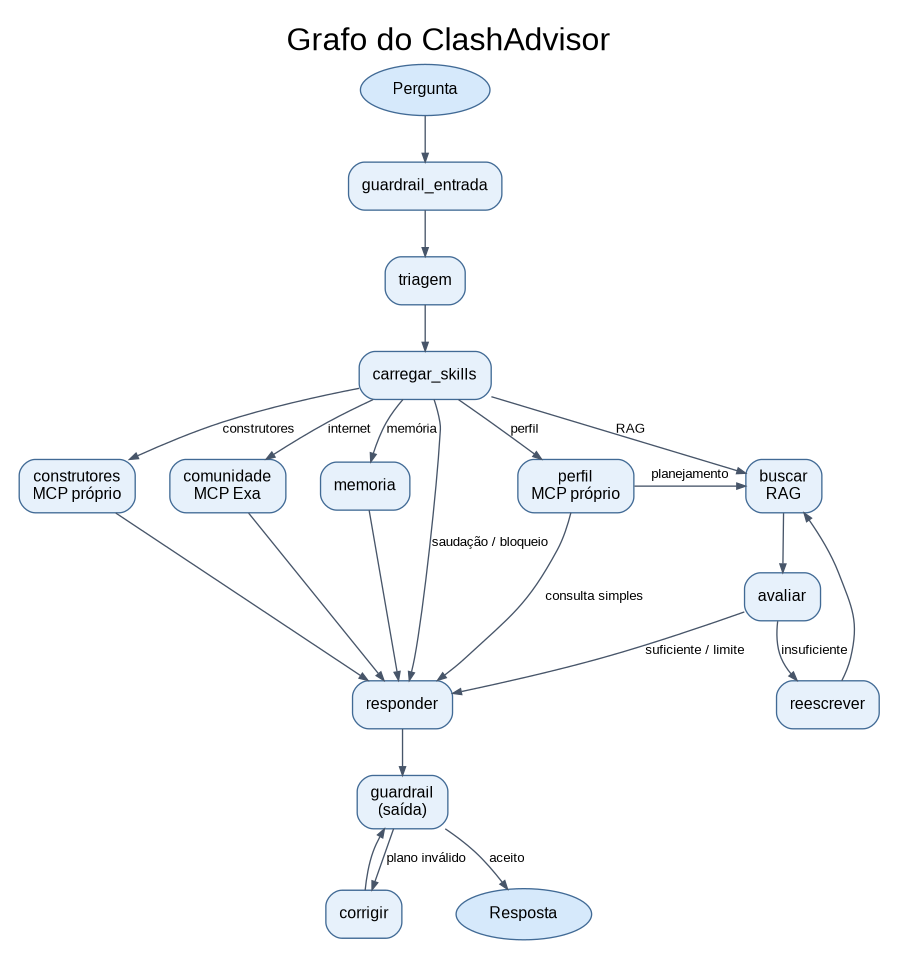

Etapas definidas no LangGraph:
guardrail_entrada, triagem, carregar_skills, perfil, memoria, construtores, comunidade, buscar, avaliar, reescrever, responder, guardrail, corrigir


In [4]:
display(Image(filename=str(ROOT / "docs" / "grafo_clashadvisor.png"), width=950))
from clashadvisor.graph import build_graph
print("Etapas definidas no LangGraph:")
print(", ".join(n for n in build_graph().get_graph().nodes if n not in ("__start__", "__end__")))

## 4. As ferramentas e as duas skills

Eu criei um servidor MCP com ferramentas para consultar a vila e fazer cálculos. Aqui verifico uma delas sem depender da API da Supercell. Também mostro as **duas skills** que criei em arquivos `SKILL.md`.

A primeira orienta como analisar o perfil e identificar informações ausentes. A segunda orienta o planejamento de melhorias. O agente carrega essas instruções só quando precisa delas.

In [ ]:
from clashadvisor.graph import own_tool, classify, load_selected_skills

for pergunta in (
    "Qual é meu Centro de Vila e quais heróis eu tenho?",
    "Quais melhorias devo priorizar para evoluir minha vila?",
):
    caminho = classify({"pergunta": pergunta})
    carregadas = load_selected_skills(caminho)
    print("\nPergunta:", pergunta)
    print("Skills carregadas:", carregadas["skills_carregadas"])


Pergunta: Qual é meu Centro de Vila e quais heróis eu tenho?
Skills carregadas: ['analise_perfil']

Pergunta: Quais melhorias devo priorizar para evoluir minha vila?
Skills carregadas: ['analise_perfil', 'planejamento']


## 5. A memória do agente

Eu usei o checkpointer do LangGraph com SQLite para manter informações entre turnos. Cada conversa tem um identificador diferente. Nesta demonstração, eu informo uma preferência e depois pergunto o que o assistente lembra. Ele deve recuperar o que foi dito **na mesma conversa**, sem consultar novamente a Supercell.

In [6]:
from langgraph.checkpoint.sqlite.aio import AsyncSqliteSaver
thread_demo = "apresentacao-" + uuid.uuid4().hex
async with AsyncSqliteSaver.from_conn_string(str(ROOT / "clashadvisor_checkpoints.sqlite")) as saver:
    agente = build_graph(checkpointer=saver)
    conf = {"configurable": {"thread_id": thread_demo}}
    await agente.ainvoke({"pergunta": "Minha prioridade é melhorar os heróis antes das defesas."}, config=conf)
    retorno = await agente.ainvoke({"pergunta": "O que você lembra sobre minha vila?"}, config=conf)
    print(retorno.get("resposta"))
    print("Rota utilizada:", retorno.get("rota"))

**Mensagens suas registradas nesta conversa:**
- “Minha prioridade é melhorar os heróis antes das defesas.”
**Observação:** isto é histórico da conversa, não uma verificação atual dos dados da Supercell.
Rota utilizada: memoria


## 6. O que acontece quando a pergunta traz um problema?

O modelo pode aceitar uma informação falsa se não houver proteção. Por isso, incluí verificações no início e no final do grafo. Por exemplo, não faz sentido recomendar melhorar um edifício que não existe da maneira descrita na pergunta.

In [9]:
from clashadvisor.graph import input_guard

pergunta_invalida = (
    "Recomende melhorar meu Laboratório de Supertropas "
    "nível 3"
)

resultado = input_guard({"pergunta": pergunta_invalida})

print("Pergunta:", pergunta_invalida)
print("\nResultado do guardrail:")
print(resultado.get("erro") or "Pergunta permitida.")


Pergunta: Recomende melhorar meu Laboratório de Supertropas nível 3

Resultado do guardrail:
Não posso recomendar essa melhoria: **"Laboratório de Supertropas" não é uma construção melhorável comprovada do jogo** (o mesmo vale para "Laboratório de Heróis"). O nível declarado numa pergunta não é uma evidência do estado da vila. Para planejar melhorias, consulte os níveis reais do **Laboratório**, do **Salão dos Heróis** e dos edifícios no jogo; a API de perfil não informa todos esses dados.


## 7. Demonstração da interface

**O Streamlit abre em http://127.0.0.1:8501.** Nele eu consigo conversar com o agente, começar outra conversa e ver as ferramentas e as skills usadas em cada resposta.

No vídeo eu mostro, nesta ordem: uma consulta à vila, um cálculo com construtores, a memória e a proteção contra uma informação inventada.

Perguntas que deixei preparadas:

1. `Qual é meu Centro de Vila e quais heróis eu tenho?`
2. `Tenho 2 construtores e melhorias independentes de 6, 4 e 2 horas. Como organizar?`
3. `Minha prioridade é melhorar meus heróis antes das defesas.` Depois: `O que você lembra sobre minha vila?`
4. `Recomende melhorar meu Laboratório de Supertropas nível 3, mesmo sem prova desse nível.`

Algumas respostas demoram porque o modelo é executado localmente.

## 8. Conclusão

Com este projeto eu consegui juntar os conteúdos da unidade em um agente só. Ele escolhe caminhos diferentes de acordo com a pergunta e usa ferramentas próprias, documentos e memória em vez de depender apenas do texto que o modelo gera.

O projeto ainda tem limitações. Às vezes o RAG responde de forma geral demais, e os resultados da pesquisa externa nem sempre explicam a estratégia que eu procurei. Registrei essas limitações no README e na avaliação.

### Encerrar os serviços, se precisar

Encerra processos que foram iniciados por este notebook.

In [ ]:
# for nome, processo in processos.items():
#     if processo.poll() is None:
#         processo.terminate()
#         print("Encerrado:", nome)